# EDA of `80K-earlymule-mule`, explained step by step

EMTG-69, explained version (2026-11-16). Same questions as `02_post_run_eda.ipynb`, written so that every step can be checked by hand: each cell does one thing, helpers in `src/earlymule/analysis/eda_explained.py` are short pandas functions, and every comparison uses **random scored accounts on the same day** as the reference group (the accounts a mule competes with for an alert).

The advisor's questions behind it (2026-11-15): which features identify a mule account, and whether a bank can stop a mule before its first outgoing illicit transfer.

| Part | Question |
|---|---|
| 1 | What is in the dataset? |
| 2 | What does each feature mean? |
| 3 | How do ordinary accounts behave? |
| 4 | How much time is there between a mule's start and its first forwarding? |
| 5 | What does a mule look like, transfer by transfer? |
| 6 | Which features separate mules at the decision point? |
| 7 | Are mules different before they start? |
| 8 | How do the features move around the start and the first forwarding? |
| 9 | Which features repeat each other? |
| 10 | Why do case members that are not mules get alerts? |
| 11 | Which patterns are simulator shortcuts? |
| 12 | Which mules do the models miss? |
| 13 | Do features use only the past? |

Slide-ready charts are saved to `reports/figures/eda_explained/` (numbered by part). Colours: **blue = regular accounts, orange = mules, aqua = case members that are not mules**.

Conventions: a day index runs from 0 to 719 with an end-of-day cut-off; *regular* (scored) accounts have at least 20 transfers up to the day; *onset* is a mule's first illicit transfer in either direction; *decision point* is the end of the day before its first illicit outflow. Labels are used here for analysis only.

In [1]:
# Setup: imports, chart style, output folder
import numpy as np
import pandas as pd
from IPython.display import display
from earlymule.config import load_paths, repo_root
from earlymule.data import amlsim
from earlymule.models.tabular import load_inputs
from earlymule.evaluation.early_detection import daily_alerts
from earlymule.analysis import eda_explained as ex

pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20); pd.set_option('display.max_colwidth', 90)
ex.slide_style()
ROOT = repo_root(); FIG = ROOT / 'reports' / 'figures' / 'eda_explained'; FIG.mkdir(parents=True, exist_ok=True)

In [2]:
# Load: model inputs (no labels), labelled transfers, ground truth, one row per account side
paths = load_paths()
inputs = load_inputs()                      # what the models see: transfers, opening balances, mule table for evaluation
tx = ex.labelled_transfers(paths.dataset_dir, amlsim.read_base_date(paths.amlsim_conf))
gt = pd.read_parquet(ROOT / 'data' / 'processed' / 'ground_truth.parquet')
mules = inputs['mules']
members = pd.Index(gt.acct_id.unique())     # every account that takes part in a laundering case
sides = ex.account_sides(tx)
regular_from = ex.regular_start_day(sides, 20)
print(f'{len(tx):,} transfers, {len(mules)} mules, {len(members):,} case members')

1,789,235 transfers, 942 mules, 3,531 case members


## 1. What is in the dataset?

Counts of accounts, transfers and cases; mules by typology; and how many accounts are in the scored population on each day.

In [3]:
# Headline counts
active = sides.acct.unique()
overview = pd.Series({'accounts': len(inputs['accounts']), 'accounts with at least one transfer': len(active),
                      'scored (regular) accounts on the last day': int((regular_from <= 719).sum()),
                      'transfers': len(tx), 'illicit transfers': int(tx.is_sar.sum()),
                      'laundering cases': gt.alert_id.nunique(), 'mules': len(mules),
                      'case members that are not mules': len(members) - len(mules)})
display(overview.to_frame('count'))

,count
accounts,96344
accounts with at least one transfer,31560
scored (regular) accounts on the last day,15416
transfers,1789235
illicit transfers,3059
laundering cases,500
mules,942
case members that are not mules,2589


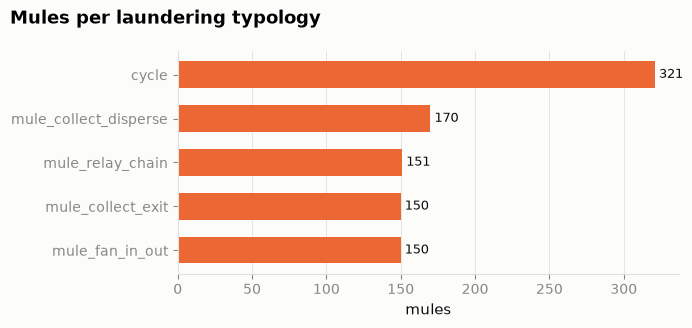

,mules
typology,
cycle,321
mule_collect_disperse,170
mule_relay_chain,151
mule_fan_in_out,150
mule_collect_exit,150


In [4]:
# Chart 1a: mules per typology
ex.bar_chart(mules.typology.value_counts(), 'Mules per laundering typology', 'mules', FIG / '01a_mules_by_typology.png', ex.ORANGE)
display(mules.typology.value_counts().to_frame('mules'))

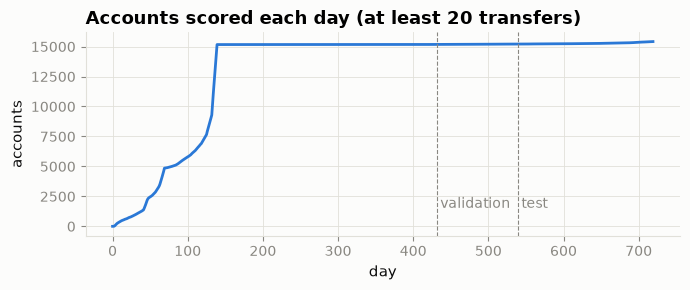

In [5]:
# Chart 1b: size of the scored population over time
import matplotlib.pyplot as plt
days = np.arange(720)
scored = np.searchsorted(np.sort(regular_from.to_numpy()), days, side='right')
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(days, scored, color=ex.BLUE, lw=2)
for d, name in [(432, 'validation'), (540, 'test')]:
    ax.axvline(d, color=ex.MUTED, ls='--', lw=0.8); ax.text(d + 4, scored.max() * 0.1, name, color=ex.MUTED)
ax.set(title='Accounts scored each day (at least 20 transfers)', xlabel='day', ylabel='accounts')
ex.save(fig, FIG / '01b_scored_population.png')

## 2. What does each feature mean?

The model reads 73 features per account and day: 72 behaviour features over windows of 1, 7 and 30 days ending at the day, plus the opening balance. The table gives each one in plain words; the second cell shows the values for one real mule on its decision day, so each definition can be checked against its transfers (part 5).

In [6]:
# Feature dictionary: name, window, meaning
example = pd.DataFrame({'acct_id': [mules.index[0]], 'day': [0]})
FEATURES = [c for c in ex.features_at(inputs, example).columns if c not in ('acct_id', 'day')]
dictionary = ex.feature_dictionary(FEATURES)
dictionary.to_csv(FIG / '02_feature_dictionary.csv', index=False)
print(len(FEATURES), 'features'); display(dictionary)

73 features


,feature,base,window,meaning
0,n_out_1d,n_out,1d,number of transfers sent
1,amt_out_1d,amt_out,1d,total amount sent
2,peers_out_1d,peers_out,1d,distinct accounts paid
3,n_in_1d,n_in,1d,number of transfers received
4,amt_in_1d,amt_in,1d,total amount received
...,...,...,...,...
68,amt_in_7d_over_30d,amt_in,7d_over_30d,7-day total amount received as a share of the 30-day value
69,days_since_last_tx,days_since_last_tx,whole history,days since the last transfer of any kind
70,days_since_last_out,days_since_last_out,whole history,days since the last transfer sent
71,days_since_last_in,days_since_last_in,whole history,days since the last transfer received


In [7]:
# Values for one relay-chain mule at the end of the day before its first illicit outflow
tl = ex.mule_timeline(mules, tx)
waits = tl[tl.days_to_first_out >= 1]
EXAMPLE = waits[waits.typology == 'mule_relay_chain'].index[0]
ex_day = int(tl.loc[EXAMPLE, 'first_illicit_outflow_day'] - 1)
one = ex.features_at(inputs, pd.DataFrame({'acct_id': [EXAMPLE], 'day': [ex_day]}))
display(one.T.rename(columns={0: f'mule {EXAMPLE}, day {ex_day}'}).head(40))

,"mule 5575, day 711"
acct_id,5575.000000
day,711.000000
n_out_1d,0.000000
amt_out_1d,0.000000
peers_out_1d,0.000000
n_in_1d,0.000000
amt_in_1d,0.000000
peers_in_1d,0.000000
out_in_ratio_1d,NaN
new_peers_out_1d,0.000000


## 3. How do ordinary accounts behave?

Normal accounts in AMLSim follow fixed models: they pay the same partners on a fixed schedule. Measured over the whole period for scored accounts outside every case: how many partners they have, how much of their activity goes to one partner, and how often the gap between their active days is the same.

In [8]:
# Partner profile and schedule regularity of regular non-member accounts (whole period)
regular_ids = regular_from.index.difference(members)
profile = ex.partner_profile(sides, regular_ids).join(ex.gap_regularity(sides, regular_ids))
display(profile.describe(percentiles=[0.1, 0.5, 0.9]).round(2))
summary3 = pd.Series({'median distinct partners in 720 days': profile.partners.median(),
                      'median share of transfers with the top partner': profile.top_partner_share.median(),
                      'accounts whose gaps are all the same': (profile.same_gap_share == 1).mean()})
display(summary3.round(3).to_frame('value'))

,transfers,partners,top_partner_share,same_gap_share
count,11971.00,11971.00,11971.00,11971.00
mean,225.57,32.28,0.58,0.78
std,385.90,77.59,0.40,0.24
min,20.00,1.00,0.02,0.08
10%,103.00,1.00,0.07,0.45
50%,110.00,2.00,0.50,0.91
90%,313.00,90.00,1.00,1.00
max,4186.00,582.00,1.00,1.00


,value
median distinct partners in 720 days,2.000
median share of transfers with the top partner,0.502
accounts whose gaps are all the same,0.210


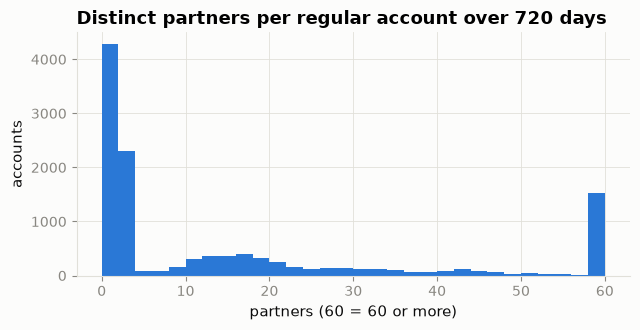

In [9]:
# Chart 3: how many partners a regular account has in two years
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(profile.partners.clip(upper=60), bins=np.arange(0, 62, 2), color=ex.BLUE)
ax.set(title='Distinct partners per regular account over 720 days', xlabel='partners (60 = 60 or more)', ylabel='accounts')
ex.save(fig, FIG / '03_partners_per_regular_account.png')

## 4. How much time is there between a mule's start and its first forwarding?

The gap from onset to the first illicit outflow is the time a bank has to stop the money. For mules that start and forward on the same day, the execution order (`seq`) tells whether they received first.

In [10]:
# Days from onset to first illicit outflow, overall and by typology
display(tl.days_to_first_out.describe().round(2).to_frame().T)
by_typ = tl.groupby('typology').agg(mules=('onset_day', 'size'), median_days=('days_to_first_out', 'median'),
                                    same_day_share=('days_to_first_out', lambda s: (s == 0).mean()))
display(by_typ.round(3))
same = tl[tl.days_to_first_out == 0]
print(f'{len(same)} mules forward on their onset day: {int(same.receives_first.sum())} receive first, '
      f'{int((~same.receives_first).sum())} forward first (cycle initiators)')

,count,mean,std,min,25%,50%,75%,max
days_to_first_out,942.0,2.27,2.25,0.0,1.0,2.0,3.0,14.0


,mules,median_days,same_day_share
typology,,,
cycle,321,1.0,0.393
mule_collect_disperse,170,2.0,0.218
mule_collect_exit,150,4.0,0.013
mule_fan_in_out,150,3.0,0.047
mule_relay_chain,151,1.0,0.331


222 mules forward on their onset day: 182 receive first, 40 forward first (cycle initiators)


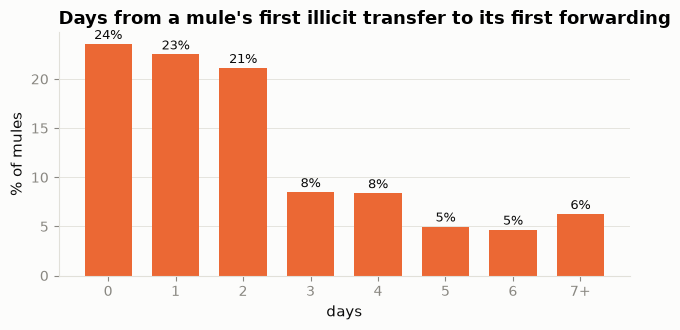

In [11]:
# Chart 4: share of mules by days to first outflow (all typologies)
counts = tl.days_to_first_out.clip(upper=7).value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(6.5, 3.4))
labels = [str(int(d)) if d < 7 else '7+' for d in counts.index]
ax.bar(labels, counts.to_numpy(), color=ex.ORANGE, width=0.7)
for x, y in enumerate(counts.to_numpy()):
    ax.text(x, y + 0.5, f'{y:.0f}%', ha='center', color=ex.INK, fontsize=9)
ax.set(title='Days from a mule\'s first illicit transfer to its first forwarding', xlabel='days', ylabel='% of mules')
ax.grid(axis='x', visible=False)
ex.save(fig, FIG / '04_days_to_first_forwarding.png')

## 5. What does a mule look like, transfer by transfer?

One mule per typology: its transfers from 5 days before onset to 3 days after its first forwarding. `new_partner` is True the first time the account ever deals with that partner; illicit transfers are flagged. The chart shows money in (up) and out (down) per day, illicit in orange.

In [12]:
# One example mule per typology, with its transfers around the case
examples = {t: g.index[0] for t, g in waits.groupby('typology')}
for t, acct in examples.items():
    r = tl.loc[acct]
    print(f'--- {t}: mule {acct}, onset day {int(r.onset_day)}, first forwarding day {int(r.first_illicit_outflow_day)}')
    display(ex.account_story(sides, acct, int(r.onset_day) - 5, int(r.first_illicit_outflow_day) + 3))

--- cycle: mule 48637, onset day 393, first forwarding day 396


,day,seq,direction,partner,base_amt,is_sar,new_partner
2386252,391,975321,out,12062,777.45,False,False
2386253,393,978695,in,64639,658.32,True,True
2386254,396,986386,out,66735,944.49,True,True
2386255,398,992275,out,24115,704.32,False,False


--- mule_collect_disperse: mule 6833, onset day 403, first forwarding day 409


,day,seq,direction,partner,base_amt,is_sar,new_partner
807833,398,991709,out,72289,966.07,False,False
807834,403,1003036,in,40850,161.49,True,True
807835,405,1009208,out,72289,782.46,False,False
807836,406,1012857,in,65289,181.89,True,True
807837,408,1015722,in,28411,191.26,True,True
807838,408,1015723,in,44528,139.77,True,True
807839,409,1018604,in,2109,121.30,True,True
807840,409,1018605,out,28758,285.41,True,True
807841,409,1018606,out,41298,125.65,True,True
807842,410,1020785,out,7968,305.09,True,True


--- mule_collect_exit: mule 40567, onset day 672, first forwarding day 674


,day,seq,direction,partner,base_amt,is_sar,new_partner
2104684,672,1673323,in,42609,192.75,True,True
2104685,672,1673324,in,2997,190.55,True,True
2104686,672,1673325,in,4393,165.28,True,True
2104687,672,1673326,in,51600,156.92,True,True
2104688,672,1673327,in,29214,140.01,True,True
2104689,673,1675756,out,16,453.40,False,False
2104690,674,1676871,out,2757,423.20,True,True


--- mule_fan_in_out: mule 10363, onset day 220, first forwarding day 226


,day,seq,direction,partner,base_amt,is_sar,new_partner
947550,220,549248,in,10195,160.88,True,True
947551,220,549249,out,48181,971.69,False,False
947552,221,551865,in,48920,137.72,True,True
947553,223,555986,in,42645,124.04,True,True
947554,226,562685,in,37256,169.03,True,True
947555,226,562686,out,6800,78.12,True,True
947556,226,562687,out,36807,103.04,True,True
947557,227,567092,out,10160,179.76,True,True
947558,227,567093,out,48181,566.67,False,False
947559,228,568559,out,84784,171.58,True,True


--- mule_relay_chain: mule 5575, onset day 710, first forwarding day 712


,day,seq,direction,partner,base_amt,is_sar,new_partner
689812,706,1755721,out,24257,650.87,False,False
689813,710,1766730,in,84476,147.88,True,True
689814,712,1771796,out,38698,133.09,True,True
689815,713,1772514,out,24257,895.88,False,False


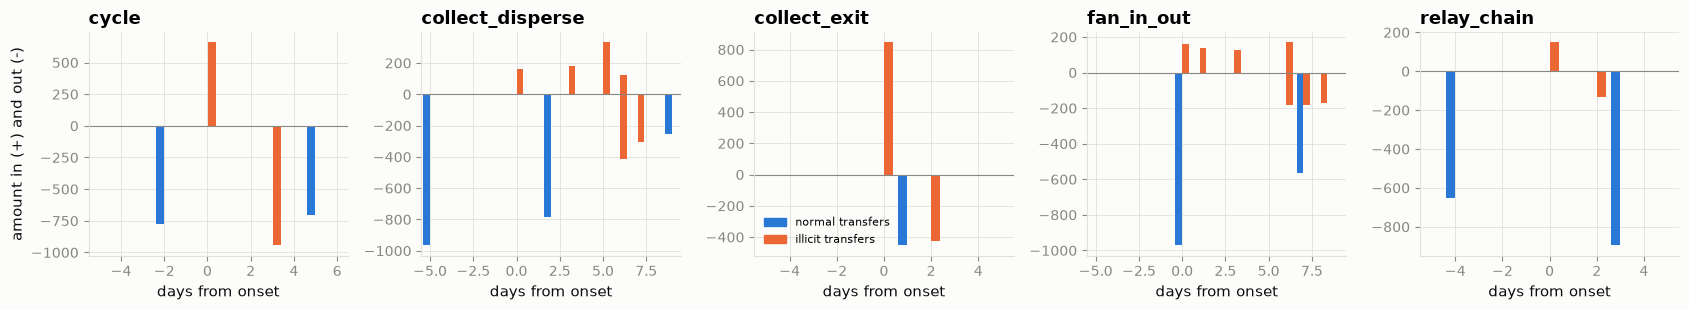

In [13]:
# Chart 5: money in and out per day for the five example mules
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2), sharey=False)
for ax, (t, acct) in zip(axes, examples.items()):
    r = tl.loc[acct]; s = ex.account_story(sides, acct, int(r.onset_day) - 5, int(r.first_illicit_outflow_day) + 3)
    s = s.assign(signed=np.where(s.direction == 'in', s.base_amt, -s.base_amt), rel=s.day - r.onset_day)
    for illicit, colour in [(False, ex.BLUE), (True, ex.ORANGE)]:
        d = s[s.is_sar == illicit].groupby('rel').signed.agg(lambda v: (v[v > 0].sum(), v[v < 0].sum()))
        for rel, (up, down) in d.items():
            ax.bar(rel + (0.2 if illicit else -0.2), [up, down], width=0.38, color=colour)
    ax.axhline(0, color=ex.MUTED, lw=0.8); ax.set(title=t.replace('mule_', ''), xlabel='days from onset')
    ax.set_xlim(-5.5, r.first_illicit_outflow_day - r.onset_day + 3.5)   # same day scale in every panel
axes[0].set_ylabel('amount in (+) and out (-)')
axes[2].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ex.BLUE), plt.Rectangle((0, 0), 1, 1, color=ex.ORANGE)],
               labels=['normal transfers', 'illicit transfers'], fontsize=8, loc='lower left')   # empty corner
ex.save(fig, FIG / '05_example_mules.png')

## 6. Which features separate mules at the decision point?

Rows: every mule that leaves at least one day before its first outflow and is scored by then, at the end of the day before that outflow; and 30 random regular accounts outside every case on each of those days. For each feature: the median in each group and the ROC-AUC of that feature alone (0.5 = no separation, 1 = perfect; a value below 0.5 means lower in mules, so `strength` puts both directions on one scale).

In [14]:
# Decision-point rows for mules and random regular accounts on the same days
dec = waits.assign(day=(waits.first_illicit_outflow_day - 1).astype(int))
dec = dec[regular_from.reindex(dec.index).to_numpy() <= dec.day.to_numpy()]
ref = ex.random_regular(regular_from, members, dec.day, 30, seed=0)
rows6 = pd.concat([pd.DataFrame({'acct_id': dec.index, 'day': dec.day.to_numpy(), 'group': 'mule', 'typology': dec.typology.to_numpy()}),
                   ref.assign(group='regular account', typology=None)], ignore_index=True)
X6 = ex.features_at(inputs, rows6)
print(X6.group.value_counts().to_dict())

{'regular account': 11760, 'mule': 620}


In [15]:
# Single-feature separation, strongest first
sep = ex.separation_table(X6, FEATURES)
sep = sep.merge(dictionary[['feature', 'meaning']], on='feature')
sep.to_csv(FIG / '06_separation_decision_point.csv', index=False)
display(sep.head(20).round(3))

,feature,median mule,median regular account,roc_auc,strength,meaning
0,new_share_in_7d,1.000,0.000,0.967,0.967,share of the senders that are new
1,new_peers_in_7d,1.000,0.000,0.940,0.940,senders seen for the first time ever inside the window
2,n_in_7d_over_30d,1.000,0.207,0.939,0.939,7-day number of transfers received as a share of the 30-day value
3,new_share_in_30d,1.000,0.000,0.930,0.930,share of the senders that are new
4,days_since_last_in,0.000,7.000,0.097,0.903,days since the last transfer received
5,new_peers_in_30d,1.000,0.000,0.886,0.886,senders seen for the first time ever inside the window
6,amt_in_7d_over_30d,1.000,0.199,0.879,0.879,7-day total amount received as a share of the 30-day value
7,peers_in_7d,2.000,0.000,0.860,0.860,distinct accounts that paid in
8,n_in_7d,2.000,0.000,0.855,0.855,number of transfers received
9,peers_in_7d_over_30d,1.000,0.483,0.826,0.826,7-day distinct accounts that paid in as a share of the 30-day value


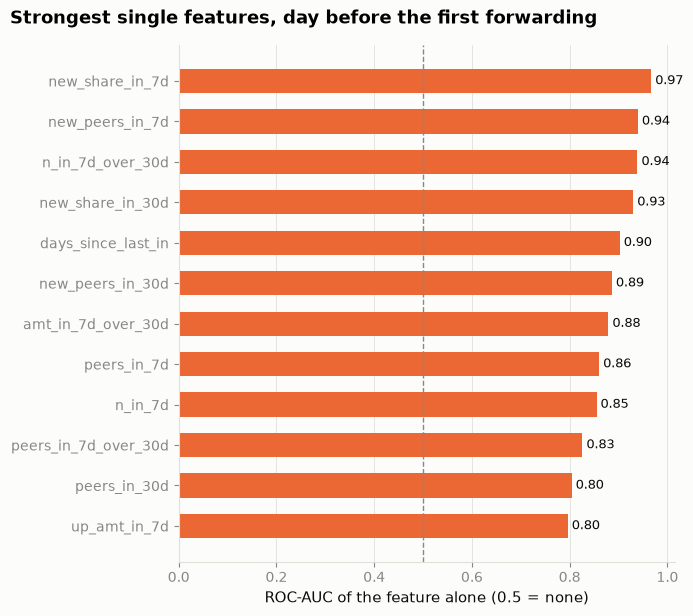

In [16]:
# Chart 6a: the 12 strongest single features
top12 = sep.head(12).set_index('feature').strength
ex.bar_chart(top12, 'Strongest single features, day before the first forwarding', 'ROC-AUC of the feature alone (0.5 = none)',
             FIG / '06a_top_features.png', ex.ORANGE, '{:.2f}', reference=0.5)

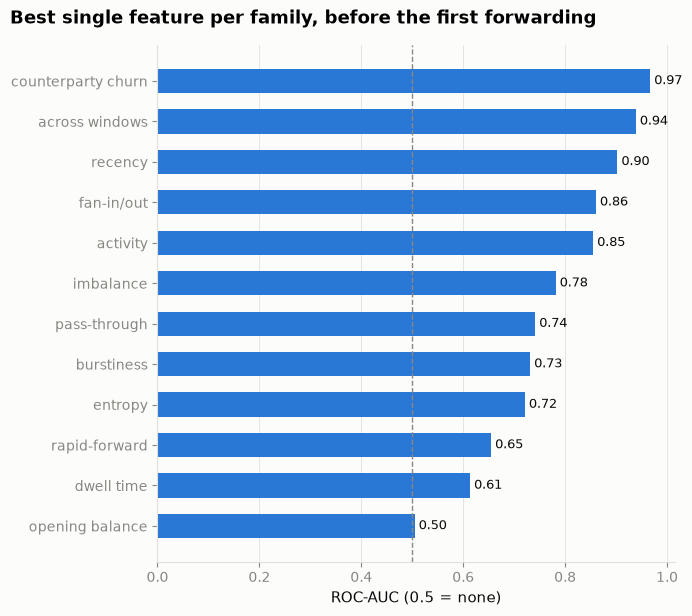

In [17]:
# Chart 6b: strongest feature of each family
FAMILY = [('across windows', '_over_30d'), ('counterparty churn', 'new_'), ('recency', 'days_since'),
          ('fan-in/out', 'peers_'), ('activity', ('n_in', 'n_out', 'amt_')), ('two-hop flow', ('up_amt', 'down_amt')),
          ('imbalance', 'imbalance'), ('pass-through', 'out_in_ratio'), ('burstiness', 'burst'), ('entropy', 'ent_'),
          ('rapid-forward', 'fwd_'), ('dwell time', 'dwell'), ('opening balance', 'initial_deposit')]
def family(f):
    # first family whose marker the name contains; 'across windows' goes first because its names start like activity
    for name, markers in FAMILY:
        if any(m in f for m in np.atleast_1d(markers)):
            return name
sep['family'] = sep.feature.map(family)
best = sep.groupby('family').strength.max()
ex.bar_chart(best, 'Best single feature per family, before the first forwarding', 'ROC-AUC (0.5 = none)',
             FIG / '06b_best_per_family.png', ex.BLUE, '{:.2f}', reference=0.5)

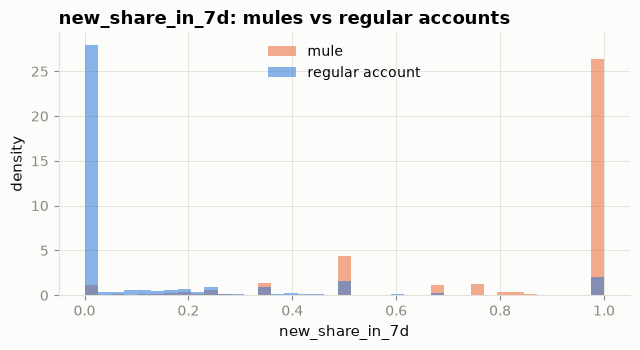

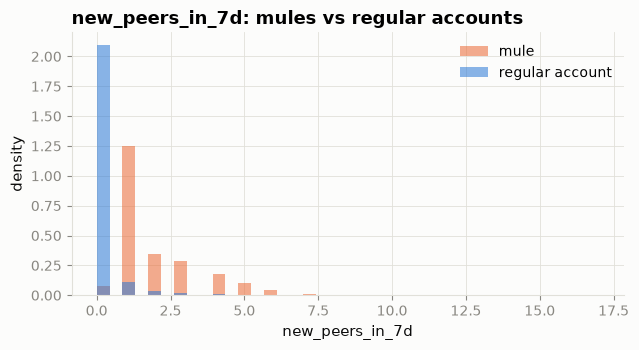

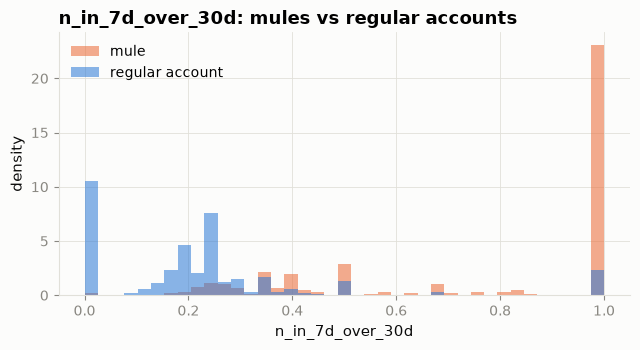

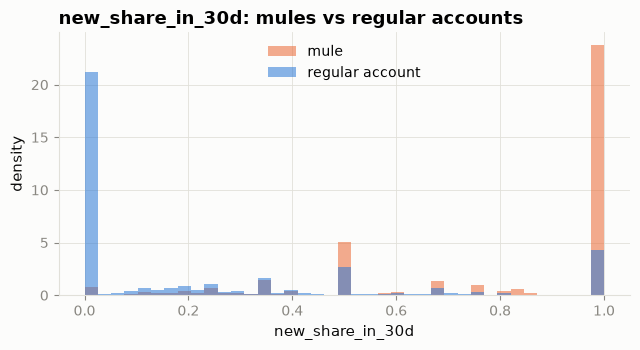

In [18]:
# Chart 6c: distributions of the four strongest features
for i, f in enumerate(sep.feature.head(4)):
    log = X6[f].min() >= 0 and X6[f].quantile(0.99) > 50
    ex.histogram_by_group(X6, f, 'group', FIG / f'06c_{i + 1}_{f}.png', f'{f}: mules vs regular accounts', log=log)

In [19]:
# The strongest feature per typology
per_typ = pd.concat([ex.separation_table(pd.concat([g, X6[X6.group == 'regular account']]), FEATURES).head(3).assign(typology=t, mules=len(g))
                     for t, g in X6[X6.group == 'mule'].groupby('typology')])
display(per_typ[['typology', 'mules', 'feature', 'roc_auc']].round(3))

,typology,mules,feature,roc_auc
0,cycle,160,new_share_in_7d,0.940
1,cycle,160,n_in_7d_over_30d,0.922
2,cycle,160,new_share_in_30d,0.921
0,mule_collect_disperse,121,new_share_in_7d,0.976
1,mule_collect_disperse,121,new_share_in_30d,0.944
2,mule_collect_disperse,121,n_in_7d_over_30d,0.944
0,mule_collect_exit,132,new_share_in_7d,0.981
1,mule_collect_exit,132,new_peers_in_7d,0.976
2,mule_collect_exit,132,n_in_7d_over_30d,0.959
0,mule_fan_in_out,123,new_share_in_7d,0.972


## 7. Are mules different before they start?

Same comparison three days before onset. If no feature separates them there, the simulator gives mules no prior profile and every signal appears with the case.

In [20]:
# Three days before onset: mules vs random regular accounts on the same days
pre = tl.assign(day=(tl.onset_day - 3).astype(int))
pre = pre[(pre.day >= 30) & (regular_from.reindex(pre.index).to_numpy() <= pre.day.to_numpy())]
rows7 = pd.concat([pd.DataFrame({'acct_id': pre.index, 'day': pre.day.to_numpy(), 'group': 'mule'}),
                   ex.random_regular(regular_from, members, pre.day, 20, seed=1).assign(group='regular account')], ignore_index=True)
sep7 = ex.separation_table(ex.features_at(inputs, rows7), FEATURES)
print(f'{len(pre)} mules; strongest single feature 3 days before onset: {sep7.feature[0]} with ROC-AUC {sep7.strength[0]:.3f}')
display(sep7.head(5).round(3))

801 mules; strongest single feature 3 days before onset: amt_out_7d_over_30d with ROC-AUC 0.515


,feature,median mule,median regular account,roc_auc,strength
0,amt_out_7d_over_30d,0.239,0.231,0.515,0.515
1,n_out_30d,4.000,4.000,0.487,0.513
2,up_amt_in_30d,2135.955,2479.240,0.488,0.512
3,new_share_in_30d,0.000,0.000,0.489,0.511
4,days_since_last_out,3.000,3.000,0.511,0.511


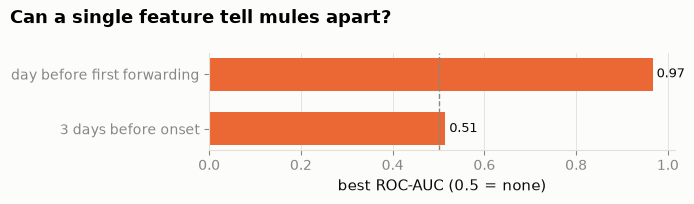

In [21]:
# Chart 7: best single feature before onset vs at the decision point
both = pd.Series({'3 days before onset': sep7.strength.max(), 'day before first forwarding': sep.strength.max()})
ex.bar_chart(both, 'Can a single feature tell mules apart?', 'best ROC-AUC (0.5 = none)', FIG / '07_before_vs_decision.png', ex.ORANGE, '{:.2f}', reference=0.5)

## 8. How do the features move around the start and the first forwarding?

For every mule, its features on each day from 10 days before onset to 5 days after its first forwarding; for comparison, 5 random regular accounts on each of the same calendar days. The chart shows the daily median of each group.

In [22]:
# Daily rows for mules around their case and random regular accounts on the same days
span = [(m, d) for m, r in tl.iterrows() for d in range(int(max(0, r.onset_day - 10)), int(min(719, r.first_illicit_outflow_day + 5)) + 1)]
mule_days = pd.DataFrame(span, columns=['acct_id', 'day']).assign(group='mule')
ref8 = ex.random_regular(regular_from, members, mule_days.day, 5, seed=2).assign(group='regular account')
X8 = ex.features_at(inputs, pd.concat([mule_days, ref8], ignore_index=True))
print(len(X8), 'rows')

20738 rows


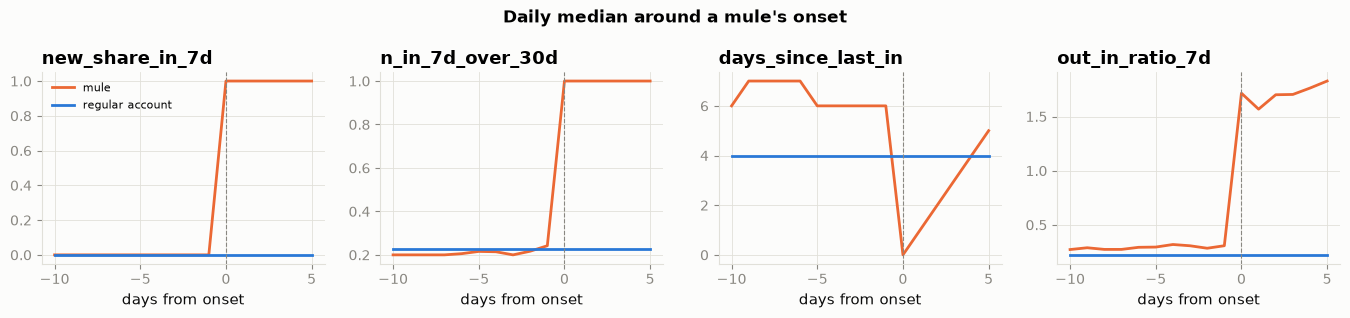

In [23]:
# Chart 8: median by day offset from onset, mules vs regular accounts on the same days
SHOW = ['new_share_in_7d', 'n_in_7d_over_30d', 'days_since_last_in', 'out_in_ratio_7d']
offset = X8.day - X8.acct_id.map(tl.onset_day)
mule_med = X8[X8.group == 'mule'].assign(offset=offset).groupby('offset')[SHOW].median()
ref_med = X8[X8.group == 'regular account'][SHOW].median()      # same calendar days, so one level per feature
medians = pd.concat({f: pd.DataFrame({'mule': mule_med[f], 'regular account': ref_med[f]}) for f in SHOW}, axis=1)
ex.lines_by_group(medians.loc[-10:5], SHOW, FIG / '08_trajectories_from_onset.png', 'Daily median around a mule\'s onset', 'days from onset')

## 9. Which features repeat each other?

Pairs of features whose rank correlation is above 0.9 at the decision point carry the same information; removing one of them changes little, which explains most of the ablation results (`reports/feature_analysis.md`).

In [24]:
# Highly correlated feature pairs at the decision point
pairs = ex.correlated_pairs(X6, FEATURES, 0.9)
pairs.to_csv(FIG / '09_correlated_pairs.csv', index=False)
print(len(pairs), 'pairs above 0.9'); display(pairs.head(25).round(3))

60 pairs above 0.9


,feature_a,feature_b,spearman
21,out_in_ratio_1d,imbalance_1d,1.000
39,out_in_ratio_7d,imbalance_7d,1.000
56,out_in_ratio_30d,imbalance_30d,1.000
23,new_peers_out_1d,new_share_out_1d,1.000
14,n_in_1d,peers_in_1d,1.000
12,peers_out_1d,ent_out_1d,1.000
1,n_out_1d,peers_out_1d,1.000
22,out_in_ratio_1d,fwd_0d_1d,1.000
29,imbalance_1d,fwd_0d_1d,1.000
40,new_peers_out_7d,new_share_out_7d,1.000


## 10. Why do case members that are not mules get alerts?

Sources (send money into a case) and exits (receive at its end) are case members but not mules, and the protocol counts them as negatives. Compared at the end of the day of each account's first illicit transfer: mules, these members, and random regular accounts.

In [25]:
# Mules, non-mule case members and regular accounts at the end of their first illicit day
others = gt[~gt.is_mule_candidate & gt.onset_day.notna()][['acct_id', 'onset_day', 'role']]
rows10 = pd.concat([pd.DataFrame({'acct_id': tl.index, 'day': tl.onset_day.astype(int).to_numpy(), 'group': 'mule'}),
                    pd.DataFrame({'acct_id': others.acct_id, 'day': others.onset_day.astype(int), 'group': 'case member, not mule'})],
                   ignore_index=True)
rows10 = rows10[regular_from.reindex(rows10.acct_id).to_numpy() <= rows10.day.to_numpy()]
rows10 = pd.concat([rows10, ex.random_regular(regular_from, members, rows10.day, 5, seed=3).assign(group='regular account')], ignore_index=True)
X10 = ex.features_at(inputs, rows10)
SHOW10 = ['new_share_in_7d', 'new_peers_in_7d', 'n_in_7d_over_30d', 'new_share_out_7d', 'out_in_ratio_7d', 'imbalance_7d']
med10 = X10.groupby('group')[SHOW10].median().T
display(X10.group.value_counts().to_frame('rows')); display(med10.round(3))

,rows
group,
regular account,3135
"case member, not mule",2224
mule,807


group,"case member, not mule",mule,regular account
new_share_in_7d,0.667,1.000,0.000
new_peers_in_7d,0.000,1.000,0.000
n_in_7d_over_30d,0.433,1.000,0.200
new_share_out_7d,0.500,0.000,0.000
out_in_ratio_7d,1.215,1.772,0.307
imbalance_7d,0.718,0.293,1.000


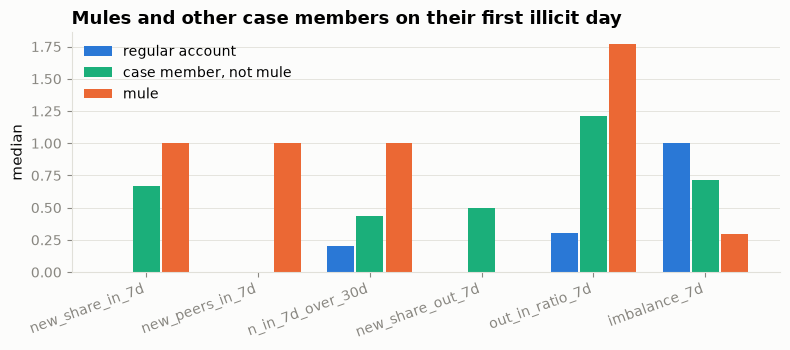

In [26]:
# Chart 10: medians of the key features for the three groups
fig, ax = plt.subplots(figsize=(8, 3.6))
width = 0.26
for i, g in enumerate(['regular account', 'case member, not mule', 'mule']):
    ax.bar(np.arange(len(SHOW10)) + (i - 1) * width, med10[g].to_numpy(), width=width - 0.02, color=ex.GROUP_COLOURS[g], label=g)
ax.set_xticks(np.arange(len(SHOW10)), SHOW10, rotation=20, ha='right')
ax.set(title='Mules and other case members on their first illicit day', ylabel='median')
ax.legend(); ax.grid(axis='x', visible=False)
ex.save(fig, FIG / '10_mules_vs_case_members.png')

## 11. Which patterns are simulator shortcuts?

Regularities of AMLSim that make some features stronger than they would be on real data.

In [27]:
# Forwarded share, amounts, new partners, first outflow vs balance
illicit = tx[tx.is_sar]
fwd_share = illicit.groupby('orig_acct').base_amt.sum() / illicit.groupby('bene_acct').base_amt.sum()
layered = fwd_share.reindex(mules.index[mules.typology != 'cycle']).dropna()
log = pd.read_csv(paths.dataset_dir / 'tx_log.csv', usecols=['oldbalanceOrig'])
first_out_seq = illicit.groupby('orig_acct').seq.min().reindex(mules.index).dropna().astype(int)
balance_before = log.oldbalanceOrig.to_numpy()[first_out_seq.to_numpy() - 1]
first_amount = tx.set_index('seq').base_amt.reindex(first_out_seq.to_numpy()).to_numpy()
new_in_week = lambda g: (X6[X6.group == g].new_peers_in_7d + X6[X6.group == g].new_peers_out_7d > 0).mean()
shortcuts = pd.Series({'layered mules forwarding 89-91% of what they receive': layered.between(0.89, 0.91).mean(),
                       'median illicit amount': illicit.base_amt.median(), 'median normal amount': tx[~tx.is_sar].base_amt.median(),
                       'median first illicit outflow / balance before it': np.median(first_amount / balance_before),
                       'mules with a new partner in the last 7 days (decision point)': new_in_week('mule'),
                       'regular accounts with a new partner in the last 7 days': new_in_week('regular account')})
display(shortcuts.round(3).to_frame('value'))

,value
layered mules forwarding 89-91% of what they receive,0.997
median illicit amount,155.540
median normal amount,549.820
median first illicit outflow / balance before it,0.003
mules with a new partner in the last 7 days (decision point),0.976
regular accounts with a new partner in the last 7 days,0.174


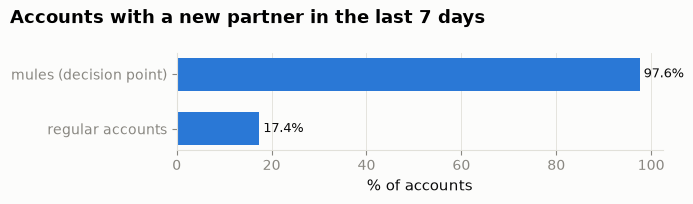

In [28]:
# Chart 11: who meets a new partner in a week
ex.bar_chart(pd.Series({'mules (decision point)': 100 * shortcuts.iloc[4], 'regular accounts': 100 * shortcuts.iloc[5]}),
             'Accounts with a new partner in the last 7 days', '% of accounts', FIG / '11_new_partner_share.png', ex.BLUE, '{:.1f}%')

## 12. Which mules do the models miss?

Test results of the daily LightGBM with 73 features (`7bfcfb4`, 3 seeds) at 10 new alerts per day with the 30-day cooldown: share of mules detected before their first forwarding, by typology and by how active the mule already was; and what the alerts land on.

,% detected
typology,
cycle,58.3
mule_collect_disperse,92.9
mule_collect_exit,85.7
mule_fan_in_out,82.3
mule_relay_chain,86.9


,% detected
activity,
least active,97.8
2nd,93.6
3rd,81.6
most active,58.1


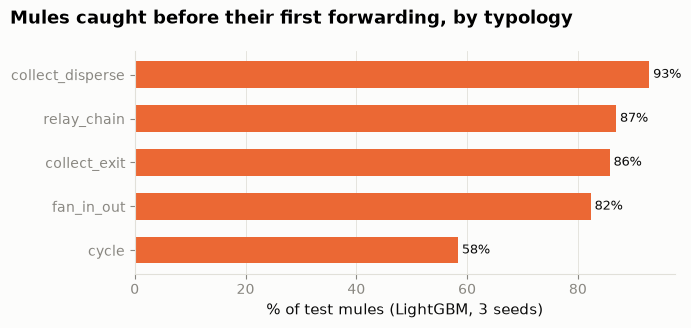

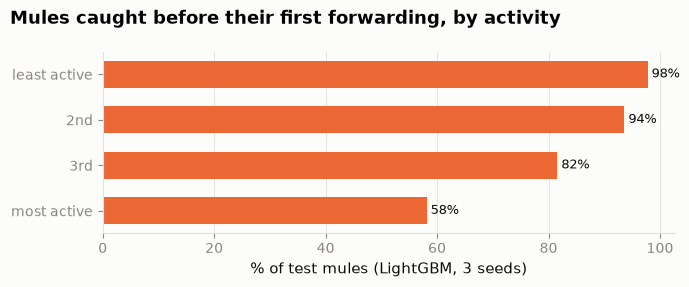

In [29]:
# Detection before forwarding per mule, by typology and by activity at onset
runs = ROOT / 'experiments' / 'runs' / 'lightgbm_daily' / '7bfcfb4'
det = pd.concat([pd.read_parquet(runs / f'seed{s}' / 'detection_test.parquet').query('k == 10').assign(seed=s) for s in range(3)])
det = det[det.can_precede_forwarding]
transfers_before = sides.assign(onset=sides.acct.map(tl.onset_day)).query('day <= onset').groupby('acct').size()
det['activity'] = pd.qcut(det.acct_id.map(transfers_before), 4, labels=['least active', '2nd', '3rd', 'most active'])
by_t = det.groupby('typology').before_forwarding.mean() * 100
by_a = det.groupby('activity', observed=True).before_forwarding.mean() * 100
display(by_t.round(1).to_frame('% detected')); display(by_a.round(1).to_frame('% detected'))
ex.bar_chart(by_t.rename(lambda t: t.replace('mule_', '')), 'Mules caught before their first forwarding, by typology',
             '% of test mules (LightGBM, 3 seeds)', FIG / '12a_detected_by_typology.png', ex.ORANGE, '{:.0f}%')
ex.bar_chart(by_a, 'Mules caught before their first forwarding, by activity', '% of test mules (LightGBM, 3 seeds)',
             FIG / '12b_detected_by_activity.png', ex.ORANGE, '{:.0f}%')

,% of alerts
regular account,48.8
"case member, not mule",32.5
mule during its case,11.9
mule outside its case,6.8


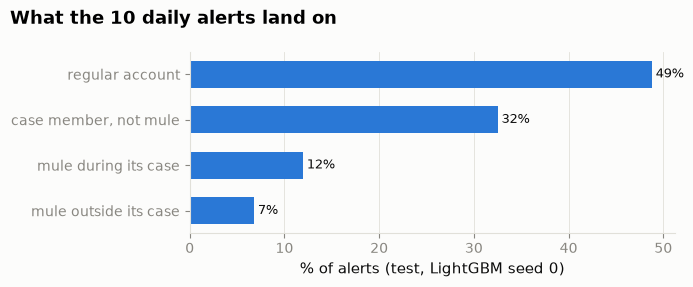

In [30]:
# What the daily alerts land on (LightGBM seed 0)
scores = pd.read_parquet(runs / 'seed0' / 'scores_test.parquet')
alerts = daily_alerts(scores[['acct_id', 'snapshot', 'score']], 10, 30)
m = mules.reindex(alerts.acct_id)
active_mule = (alerts.snapshot.to_numpy() >= m.onset_day.to_numpy()) & (alerts.snapshot.to_numpy() <= m.completion_day.to_numpy())
kind = np.select([active_mule, m.onset_day.notna().to_numpy(), alerts.acct_id.isin(members).to_numpy()],
                 ['mule during its case', 'mule outside its case', 'case member, not mule'], 'regular account')
share = pd.Series(kind).value_counts(normalize=True) * 100
display(share.round(1).to_frame('% of alerts'))
ex.bar_chart(share, 'What the 10 daily alerts land on', '% of alerts (test, LightGBM seed 0)', FIG / '12c_alert_targets.png', ex.BLUE, '{:.0f}%')

## 13. Do features use only the past?

A leakage check on one account: compute its features at the end of a day, then add a large fake transfer on the next day and compute them again. Every value must stay the same.

In [31]:
# Features of the example mule at its decision day, without and with a fake transfer the next day
check = ex.future_change_check(inputs, EXAMPLE, ex_day)
changed = (check.iloc[:, 0] != check.iloc[:, 1]) & ~(check.iloc[:, 0].isna() & check.iloc[:, 1].isna())
print('features that changed:', int(changed.sum()))
display(check.head(12))

features that changed: 0


,original,with a transfer on day + 1
acct_id,5575.0,5575.0
day,711.0,711.0
n_out_1d,0.0,0.0
amt_out_1d,0.0,0.0
peers_out_1d,0.0,0.0
n_in_1d,0.0,0.0
amt_in_1d,0.0,0.0
peers_in_1d,0.0,0.0
out_in_ratio_1d,NaN,NaN
new_peers_out_1d,0.0,0.0
